## Chủ đề số 14: Bank marketing
## Bài toán: Dự đoán khách hàng có đăng ký gửi tiền kỳ hạn hay không (Yes/No) 
## Loại bài toán: Classification

### Tập dữ liệu: UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)
### Sử dụng 4 thuật toán: Logistic Regression, KNN, Decision Tree, RandomForest
### Độ đo: F1, Recall, ROC-AUC

### 1. Giới thiệu bài toán và dữ liệu

#### 1.1. Bài toán

- **Bối cảnh:** dữ liệu ghi lại các cuộc gọi marketing trực tiếp của một ngân hàng nhằm mời khách hàng gửi tiền kỳ hạn.
- **Mục tiêu:** dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không, giúp ngân hàng ưu tiên liên hệ nhóm khách tiềm năng và giảm chi phí cuộc gọi.
- **Input:** thông tin khách hàng và chiến dịch marketing (tuổi, nghề nghiệp, lịch sử liên hệ, chỉ số kinh tế vĩ mô...).
- **Output:** `yes` (đăng ký) hoặc `no` (không đăng ký).
- **Loại bài toán:** học có giám sát, phân loại nhị phân (Classification).

#### 1.2. Dữ liệu

Nguồn: UCI Bank Marketing, tệp `bank-additional-full.csv`, gồm 41.188 mẫu và 21 cột (20 thuộc tính và biến mục tiêu `y`).

| Nhóm thuộc tính | Các cột |
|---|---|
| Thông tin khách hàng | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` |
| Thông tin lần liên hệ hiện tại | `contact`, `month`, `day_of_week`, `duration` |
| Lịch sử chiến dịch | `campaign`, `pdays`, `previous`, `poutcome` |
| Chỉ số kinh tế vĩ mô | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` |
| Biến mục tiêu | `y` |

Cột `duration` (thời lượng cuộc gọi) chỉ biết sau khi cuộc gọi kết thúc nên sẽ được loại bỏ ở mục 3 để tránh rò rỉ thông tin.


In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT_DIR = Path.cwd().resolve().parents[1]
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.config import PROCESSED_DATA_DIR

X_train_df = pd.read_csv(PROCESSED_DATA_DIR / "X_train.csv")
X_test_df = pd.read_csv(PROCESSED_DATA_DIR / "X_test.csv")
y_train = pd.read_csv(PROCESSED_DATA_DIR / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(PROCESSED_DATA_DIR / "y_test.csv").squeeze("columns")

X_train = X_train_df.values
X_test = X_test_df.values
feature_names = X_train_df.columns.to_numpy()

In [2]:
import json, os, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

from src.config import RESULTS_DIR

def save_experiment(exp_name, model, params, y_test, y_pred, y_proba, root=RESULTS_DIR):
    """Lưu toàn bộ kết quả của một thí nghiệm vào Logs/<exp_name>/"""
    folder = os.path.join(root, exp_name)
    os.makedirs(folder, exist_ok=True)

    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    }

    with open(os.path.join(folder, "params_cfg.json"), "w", encoding="utf-8") as f:
        json.dump(params, f, ensure_ascii=False, indent=2, default=str)
    with open(os.path.join(folder, "metrics.json"), "w", encoding="utf-8") as f:
        json.dump(metrics, f, ensure_ascii=False, indent=2)
    pd.DataFrame([metrics]).round(4).to_csv(os.path.join(folder, "metrics.csv"), index=False)
    pd.DataFrame({"y_true": np.asarray(y_test), "y_pred": y_pred, "y_proba": y_proba}).to_csv(
        os.path.join(folder, "predictions.csv"), index=False)
    joblib.dump(model, os.path.join(folder, "best_model.pkl"))

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No", "Yes"],
                                            cmap="Blues", ax=axes[0])
    axes[0].set_title(f"{exp_name} - Confusion Matrix")
    RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_title(f"{exp_name} - ROC Curve")
    plt.tight_layout()
    fig.savefig(os.path.join(folder, "confusion_roc.png"), dpi=150)
    plt.close(fig)
    print("Đã lưu vào:", folder)

### 7. Thuật toán Random Forest

#### 7.1. Giới thiệu thuật toán

Random Forest là thuật toán học có giám sát kết hợp nhiều cây quyết định rồi lấy kết quả bình chọn đa số. Mỗi cây được huấn luyện trên một mẫu ngẫu nhiên (bootstrap) của tập train và chỉ xét một tập con ngẫu nhiên các đặc trưng ở mỗi lần chia nhánh, nên các cây khác nhau và giảm overfitting so với một cây đơn.

- **Ưu điểm:** ổn định, ít overfitting hơn Decision Tree, không cần chuẩn hóa, cho biết độ quan trọng của đặc trưng.
- **Nhược điểm:** khó giải thích hơn một cây đơn, huấn luyện và dự đoán chậm hơn.

Cấu hình baseline: `n_estimators=300` (300 cây), `class_weight="balanced"` để xử lý mất cân bằng lớp, `random_state=42`. Các cây không giới hạn độ sâu.

#### 7.2. Huấn luyện và dự đoán

Huấn luyện mô hình trên tập train, sau đó dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test.

In [3]:
from sklearn.ensemble import RandomForestClassifier

# Khởi tạo mô hình Random Forest baseline
model_rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Huấn luyện trên tập train
model_rf.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
y_pred_rf = model_rf.predict(X_test)
y_proba_rf = model_rf.predict_proba(X_test)[:, 1]

print("Huấn luyện và dự đoán Random Forest hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_rf[:10])
print("10 xác suất dự đoán đầu tiên:", y_proba_rf[:10].round(4))

Huấn luyện và dự đoán Random Forest hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 0 0 0 0 0 0 0 0]
10 xác suất dự đoán đầu tiên: [0.01   0.7967 0.15   0.2028 0.1633 0.0067 0.0333 0.05   0.0794 0.09  ]


#### 7.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC (độ đo thầy gợi ý), bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên F1-score và Recall được ưu tiên hơn Accuracy.

In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)
auc_rf = roc_auc_score(y_test, y_proba_rf)

# Hiển thị kết quả
print("===== RANDOM FOREST BASELINE =====")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-score : {f1_rf:.4f}")
print(f"ROC-AUC  : {auc_rf:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

===== RANDOM FOREST BASELINE =====
Accuracy : 0.8930
Precision: 0.5501
Recall   : 0.2780
F1-score : 0.3694
ROC-AUC  : 0.7811

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.91      0.97      0.94      7308
         Yes       0.55      0.28      0.37       928

    accuracy                           0.89      8236
   macro avg       0.73      0.62      0.66      8236
weighted avg       0.87      0.89      0.88      8236



#### 7.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.

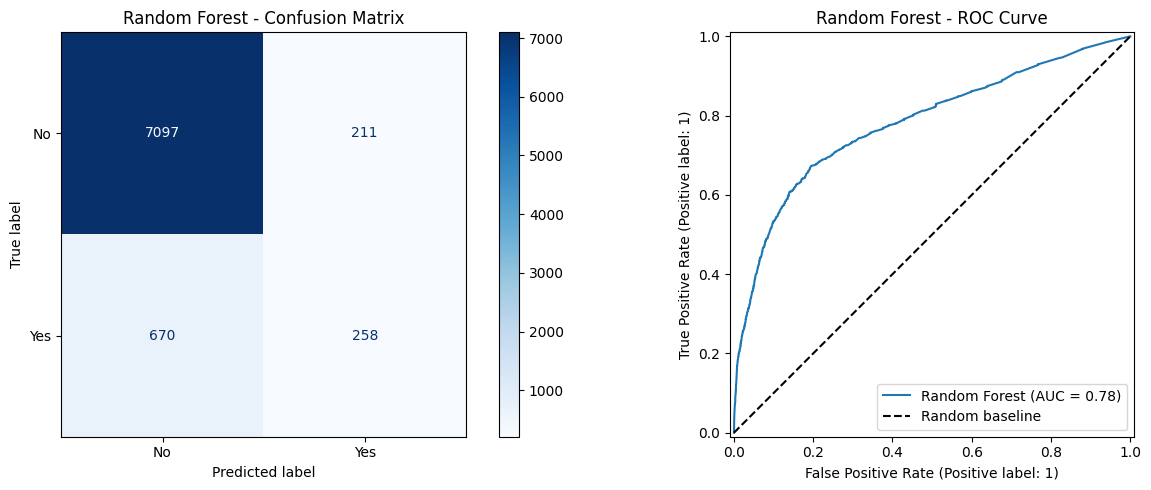

In [5]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Random Forest - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_rf,
    name="Random Forest",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Random Forest - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 7.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- Random Forest đạt F1-score ≈ 0,37, Recall ≈ 0,28 và ROC-AUC ≈ 0,78 trên tập test. ROC-AUC ở mức khá nhưng thấp hơn Logistic Regression (≈ 0,80) và Decision Tree (≈ 0,79).
- Recall chỉ khoảng 0,28: ở ngưỡng mặc định 0,5 mô hình bỏ sót khoảng 72% khách hàng thật sự đăng ký, thấp hơn nhiều so với Decision Tree và Logistic Regression (≈ 0,65) dù cùng dùng `class_weight="balanced"`. Với ngân hàng, bỏ sót khách tiềm năng là rủi ro đáng kể.
- Một nguyên nhân có thể là các cây không giới hạn độ sâu nên khớp rất sát tập train, khiến xác suất dự đoán cho lớp "yes" hiếm khi vượt ngưỡng 0,5. ROC-AUC khá cho thấy mô hình vẫn xếp hạng khách hàng tương đối tốt, vấn đề chủ yếu nằm ở ngưỡng phân loại.
- Hướng cải thiện: giới hạn `max_depth`, tăng `min_samples_leaf`, chỉnh `max_features`, hạ ngưỡng phân loại và thử SMOTE (xem mục 9 và 10). Độ quan trọng của đặc trưng được phân tích ở mục 12.

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [6]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "Random Forest (baseline)",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1-score": f1_rf,
    "ROC-AUC": auc_rf
})
all_probas["Random Forest (baseline)"] = y_proba_rf

print("Đã lưu kết quả Random Forest!")


Đã lưu kết quả Random Forest!


### 9. Xử lý mất cân bằng lớp và chỉnh ngưỡng


#### 9.4. Random Forest

##### 9.4.1. Cân bằng dữ liệu bằng SMOTE

SMOTE sinh thêm các mẫu `yes` nhân tạo bằng cách nội suy giữa các mẫu `yes` gần nhau, đến khi hai lớp có số lượng bằng nhau. Chỉ áp dụng trên **tập train**, tập test giữ nguyên để đánh giá đúng thực tế. Vì dữ liệu train sau khi sinh đã cân bằng nên mô hình dùng `class_weight=None` để không bù trừ hai lần.

Lưu ý hạn chế: dữ liệu đã One-Hot nên các mẫu nhân tạo có thể chứa giá trị thập phân ở các cột nhị phân.

In [7]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

def rf_metrics(y_true, y_pred, y_proba):
    """Tính 5 độ đo cho một phiên bản mô hình."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

def save_result(name, metrics, proba):
    """Lưu kết quả vào danh sách chung (thay dòng cũ nếu chạy lại)."""
    global all_results, all_probas
    if "all_results" not in globals():
        all_results = []
    if "all_probas" not in globals():
        all_probas = {}
    all_results[:] = [r for r in all_results if r["Model"] != name]
    all_results.append({"Model": name, **metrics})
    all_probas[name] = proba

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# Cân bằng lại tập train (không đụng tới tập test)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Phân bố lớp trước SMOTE:", dict(pd.Series(y_train).value_counts()))
print("Phân bố lớp sau SMOTE :", dict(pd.Series(y_train_smote).value_counts()))

# Huấn luyện Random Forest trên dữ liệu đã cân bằng
model_rf_smote = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
model_rf_smote.fit(X_train_smote, y_train_smote)

# Dự đoán và đánh giá trên tập test gốc
y_pred_rf_smote = model_rf_smote.predict(X_test)
y_proba_rf_smote = model_rf_smote.predict_proba(X_test)[:, 1]

metrics_rf_smote = rf_metrics(y_test, y_pred_rf_smote, y_proba_rf_smote)

print("\n===== RANDOM FOREST + SMOTE =====")
for k, v in metrics_rf_smote.items():
    print(f"{k:<10}: {v:.4f}")

# Lưu kết quả vào danh sách chung
save_result("Random Forest (SMOTE)", metrics_rf_smote, y_proba_rf_smote)

save_experiment("Experiment_17_RandomForest_SMOTE", model_rf_smote, model_rf_smote.get_params(), y_test, y_pred_rf_smote, y_proba_rf_smote)

Phân bố lớp trước SMOTE: {0: np.int64(29229), 1: np.int64(3711)}
Phân bố lớp sau SMOTE : {0: np.int64(29229), 1: np.int64(29229)}

===== RANDOM FOREST + SMOTE =====
Accuracy  : 0.8868
Precision : 0.4970
Recall    : 0.3524
F1-score  : 0.4124
ROC-AUC   : 0.7802
Đã lưu vào: C:\Users\Chau\Documents\MayHoc_nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_17_RandomForest_SMOTE


##### 9.4.2. Chỉnh ngưỡng phân loại

Mặc định mô hình dự đoán `yes` khi xác suất ≥ 0,5. Hạ ngưỡng xuống sẽ bắt được nhiều khách hàng đăng ký hơn (Recall tăng) nhưng gọi nhầm nhiều hơn (Precision giảm).

Để tránh rò rỉ thông tin, ngưỡng được **chọn trên tập train** bằng xác suất dự đoán chéo (cross-validation 5-fold, mỗi mẫu được dự đoán bởi mô hình chưa từng thấy nó), chọn ngưỡng cho F1-score cao nhất. Sau đó mới áp dụng ngưỡng đó lên tập test, không dùng tập test để chọn ngưỡng.

,Threshold,Precision,Recall,F1-score
0,0.05,0.1916,0.7766,0.3073
1,0.10,0.2697,0.6769,0.3857
2,0.15,0.3289,0.6130,0.4282
3,0.20,0.3740,0.5662,0.4504
4,0.25,0.4093,0.5125,0.4551
5,0.30,0.4416,0.4662,0.4535
6,0.35,0.4718,0.4188,0.4437
7,0.40,0.4939,0.3684,0.4220
8,0.45,0.5227,0.3223,0.3987
9,0.50,0.5432,0.2781,0.3678


Ngưỡng được chọn (F1 cao nhất trên train): 0.25


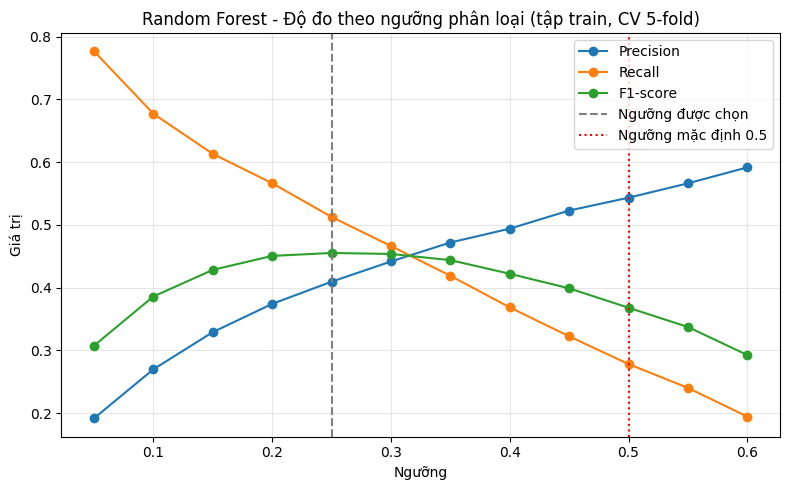

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Xác suất dự đoán chéo trên tập train bằng mô hình baseline
oof_proba_rf = cross_val_predict(
    clone(model_rf), X_train, y_train,
    cv=skf, method="predict_proba"
)[:, 1]

# Quét ngưỡng từ 0.05 đến 0.60
thresholds = np.arange(0.05, 0.65, 0.05)
rows = []
for t in thresholds:
    pred = (oof_proba_rf >= t).astype(int)
    rows.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1-score": f1_score(y_train, pred, zero_division=0),
    })

df_thr_rf = pd.DataFrame(rows)
display(df_thr_rf.round(4))

# Chọn ngưỡng có F1-score cao nhất trên tập train
best_threshold_rf = df_thr_rf.loc[df_thr_rf["F1-score"].idxmax(), "Threshold"]
print(f"Ngưỡng được chọn (F1 cao nhất trên train): {best_threshold_rf}")

# Biểu đồ Precision, Recall, F1 theo ngưỡng
plt.figure(figsize=(8, 5))
for col in ["Precision", "Recall", "F1-score"]:
    plt.plot(df_thr_rf["Threshold"], df_thr_rf[col], marker="o", label=col)
plt.axvline(best_threshold_rf, color="gray", linestyle="--", label="Ngưỡng được chọn")
plt.axvline(0.5, color="red", linestyle=":", label="Ngưỡng mặc định 0.5")
plt.title("Random Forest - Độ đo theo ngưỡng phân loại (tập train, CV 5-fold)")
plt.xlabel("Ngưỡng")
plt.ylabel("Giá trị")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

===== RANDOM FOREST + NGƯỠNG 0.25 =====
Accuracy  : 0.8618
Precision : 0.4101
Recall    : 0.5162
F1-score  : 0.4571
ROC-AUC   : 0.7811


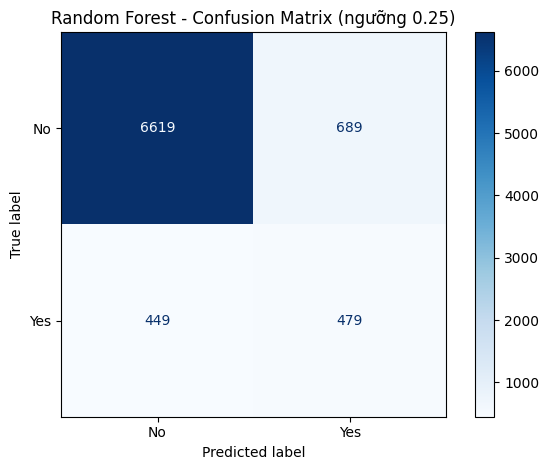

Đã lưu vào: C:\Users\Chau\Documents\MayHoc_nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_118_RandomForest_threshold


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Áp dụng ngưỡng đã chọn lên tập test (xác suất của mô hình baseline y_proba_rf)
y_pred_rf_thr = (y_proba_rf >= best_threshold_rf).astype(int)

metrics_rf_thr = rf_metrics(y_test, y_pred_rf_thr, y_proba_rf)

print(f"===== RANDOM FOREST + NGƯỠNG {best_threshold_rf} =====")
for k, v in metrics_rf_thr.items():
    print(f"{k:<10}: {v:.4f}")

# Confusion Matrix với ngưỡng mới
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf_thr,
    display_labels=["No", "Yes"], cmap="Blues"
)
plt.title(f"Random Forest - Confusion Matrix (ngưỡng {best_threshold_rf})")
plt.tight_layout()
plt.show()

# Lưu kết quả vào danh sách chung (ROC-AUC không đổi vì cùng xác suất)
save_result("Random Forest (threshold)", metrics_rf_thr, y_proba_rf)

save_experiment("Experiment_18_RandomForest_threshold", model_rf, {**model_rf.get_params(), "threshold": float(best_threshold_rf)}, y_test, y_pred_rf_thr, y_proba_rf)

##### 9.4.3. Nhận xét

**Nhận xét (điền sau khi chạy, bám sát số liệu thật):**

- Baseline: Recall = ..., F1-score = ... (xem mục 7).
- SMOTE: Recall = ..., Precision = ..., F1-score = ... So với baseline, Recall (tăng/giảm) ..., ROC-AUC (tăng/giảm) ...
- Chỉnh ngưỡng: ngưỡng được chọn = ..., Recall = ..., Precision = ..., F1-score = ... Ngưỡng thấp hơn 0,5 giúp ... nhưng đổi lại ...
- Cách nào cải thiện F1-score và Recall tốt hơn? Ý nghĩa với ngân hàng: ... (ví dụ chấp nhận gọi nhầm thêm khách để không bỏ sót khách tiềm năng).

### 10. Tinh chỉnh siêu tham số


#### 10.4. Random Forest 

##### 10.4.1. Tìm kiếm siêu tham số

Dùng `RandomizedSearchCV` (thử 20 tổ hợp ngẫu nhiên, chạy nhanh hơn GridSearchCV nhiều với không gian tìm kiếm lớn), chia dữ liệu bằng Stratified 5-fold. Tối ưu theo **F1-score** (độ đo chính), đồng thời ghi lại ROC-AUC. Các tham số tìm kiếm:

| Tham số | Giá trị thử | Ý nghĩa |
|---|---|---|
| `n_estimators` | 200, 300, 500 | Số cây |
| `max_depth` | 6, 8, 10, 12, 15, không giới hạn | Độ sâu tối đa, giới hạn để tránh overfitting |
| `min_samples_leaf` | 1, 3, 5, 10, 20 | Số mẫu tối thiểu ở nút lá |
| `min_samples_split` | 2, 10, 20 | Số mẫu tối thiểu để chia nút |
| `max_features` | `sqrt`, `log2`, 0.3 | Số đặc trưng xét ở mỗi lần chia |
| `class_weight` | `balanced`, `balanced_subsample` | Cách tăng trọng số lớp `yes` |

In [10]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Không gian tìm kiếm
param_dist_rf = {
    "n_estimators": [200, 300, 500],
    "max_depth": [6, 8, 10, 12, 15, None],
    "min_samples_leaf": [1, 3, 5, 10, 20],
    "min_samples_split": [2, 10, 20],
    "max_features": ["sqrt", "log2", 0.3],
    "class_weight": ["balanced", "balanced_subsample"],
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# n_jobs=1 cho mô hình, song song hóa ở mức RandomizedSearchCV
search_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=1),
    param_distributions=param_dist_rf,
    n_iter=20,
    scoring={"f1": "f1", "roc_auc": "roc_auc"},
    refit="f1",
    cv=skf,
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

start = time.time()
search_rf.fit(X_train, y_train)
print(f"Thời gian tìm kiếm: {(time.time() - start) / 60:.1f} phút")

print("\nTham số tốt nhất:")
for k, v in search_rf.best_params_.items():
    print(f"  {k}: {v}")
print(f"F1-score CV tốt nhất: {search_rf.best_score_:.4f}")

# Top 5 tổ hợp tốt nhất
cv_rf = pd.DataFrame(search_rf.cv_results_)
cols = ["rank_test_f1", "mean_test_f1", "mean_test_roc_auc", "params"]
display(cv_rf.sort_values("rank_test_f1")[cols].head(5).round(4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\Chau\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Thời gian tìm kiếm: 20.5 phút

Tham số tốt nhất:
  n_estimators: 200
  min_samples_split: 10
  min_samples_leaf: 3
  max_features: sqrt
  max_depth: 15
  class_weight: balanced
F1-score CV tốt nhất: 0.4953


,rank_test_f1,mean_test_f1,mean_test_roc_auc,params
14,1,0.4953,0.7984,"{'n_estimators': 200, 'min_samples_split': 10,..."
4,2,0.4941,0.7925,"{'n_estimators': 200, 'min_samples_split': 20,..."
16,3,0.4917,0.7997,"{'n_estimators': 500, 'min_samples_split': 2, ..."
6,4,0.4904,0.7891,"{'n_estimators': 500, 'min_samples_split': 10,..."
3,5,0.4872,0.7993,"{'n_estimators': 200, 'min_samples_split': 2, ..."


##### 10.4.2. Đánh giá mô hình sau tinh chỉnh

Dùng mô hình tốt nhất tìm được (đã huấn luyện lại trên toàn bộ tập train) để dự đoán và đánh giá trên tập test.

===== RANDOM FOREST (TUNED) =====
Accuracy  : 0.8729
Precision : 0.4528
Recall    : 0.6153
F1-score  : 0.5217
ROC-AUC   : 0.8120

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.95      0.91      0.93      7308
         Yes       0.45      0.62      0.52       928

    accuracy                           0.87      8236
   macro avg       0.70      0.76      0.72      8236
weighted avg       0.89      0.87      0.88      8236



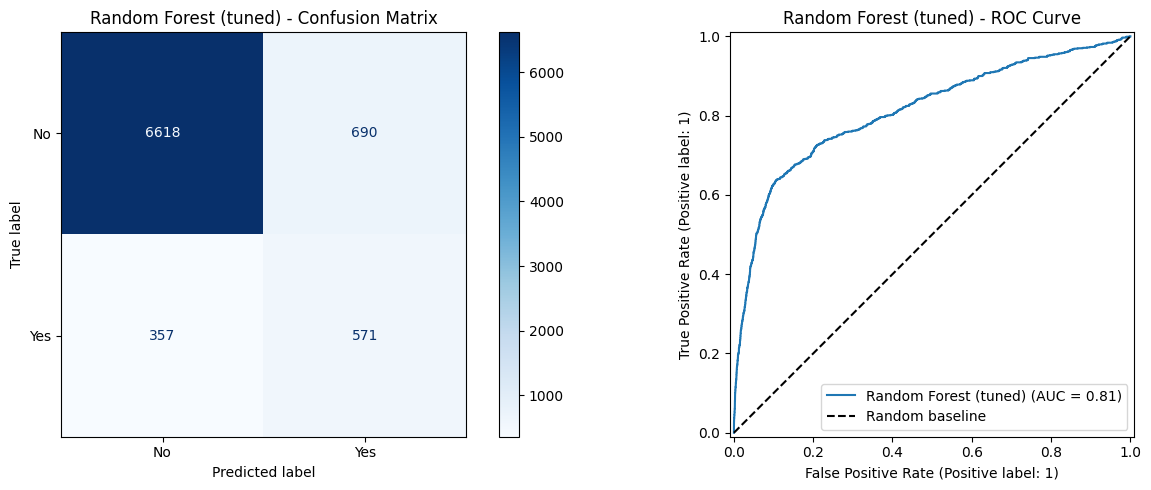

Đã lưu vào: C:\Users\Chau\Documents\MayHoc_nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_19_RandomForest_tuned


In [11]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

def rf_metrics(y_true, y_pred, y_proba):
    """Tính 5 độ đo cho một phiên bản mô hình."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

def save_result(name, metrics, proba):
    """Lưu kết quả vào danh sách chung (thay dòng cũ nếu chạy lại)."""
    global all_results, all_probas
    if "all_results" not in globals():
        all_results = []
    if "all_probas" not in globals():
        all_probas = {}
    all_results[:] = [r for r in all_results if r["Model"] != name]
    all_results.append({"Model": name, **metrics})
    all_probas[name] = proba

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

# Mô hình tốt nhất sau tinh chỉnh
model_rf_tuned = search_rf.best_estimator_
model_rf_tuned.set_params(n_jobs=-1)

y_pred_rf_tuned = model_rf_tuned.predict(X_test)
y_proba_rf_tuned = model_rf_tuned.predict_proba(X_test)[:, 1]

metrics_rf_tuned = rf_metrics(y_test, y_pred_rf_tuned, y_proba_rf_tuned)

print("===== RANDOM FOREST (TUNED) =====")
for k, v in metrics_rf_tuned.items():
    print(f"{k:<10}: {v:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test, y_pred_rf_tuned,
    target_names=["No", "Yes"], zero_division=0
))

# Confusion Matrix và ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf_tuned,
    display_labels=["No", "Yes"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Random Forest (tuned) - Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test, y_proba_rf_tuned, name="Random Forest (tuned)", ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Random Forest (tuned) - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Lưu kết quả vào danh sách chung
save_result("Random Forest (tuned)", metrics_rf_tuned, y_proba_rf_tuned)

save_experiment("Experiment_19_RandomForest_tuned", model_rf_tuned, search_rf.best_params_, y_test, y_pred_rf_tuned, y_proba_rf_tuned)

##### 10.4.3. Nhận xét

**Nhận xét (điền sau khi chạy, bám sát số liệu thật):**

- Tham số tốt nhất: `max_depth` = ..., `min_samples_leaf` = ..., `max_features` = ..., `class_weight` = ...
- So với baseline (F1 ≈ 0,37, Recall ≈ 0,28, ROC-AUC ≈ 0,78): sau tinh chỉnh F1-score = ..., Recall = ..., ROC-AUC = ...
- Việc giới hạn độ sâu và tăng `min_samples_leaf` có/không giúp Random Forest cải thiện Recall? Giải thích: ...
- So sánh với SMOTE và chỉnh ngưỡng (mục 9.4): cách nào hiệu quả nhất? Có thể kết hợp tinh chỉnh với chỉnh ngưỡng ở nửa sau để tăng Recall hơn nữa.

### 11. So sánh trước và sau tinh chỉnh

Tổng hợp và trực quan hóa hiệu năng của 4 phiên bản Random Forest qua các giai đoạn:
1. **Baseline** (`EXP-04`, `class_weight="balanced"`, ngưỡng 0.5)
2. **SMOTE** (`EXP-08`, cân bằng lớp trên tập train)
3. **Threshold Tuning** (`EXP-12`, hạ ngưỡng phân loại tối ưu theo F1 trên CV)
4. **Hyperparameter Tuning** (`EXP-16`, `RandomizedSearchCV` 5-fold)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest (baseline),0.8930,0.5501,0.2780,0.3694,0.7811
1,Random Forest (SMOTE),0.8868,0.4970,0.3524,0.4124,0.7802
2,Random Forest (threshold),0.8618,0.4101,0.5162,0.4571,0.7811
3,Random Forest (tuned),0.8729,0.4528,0.6153,0.5217,0.8120


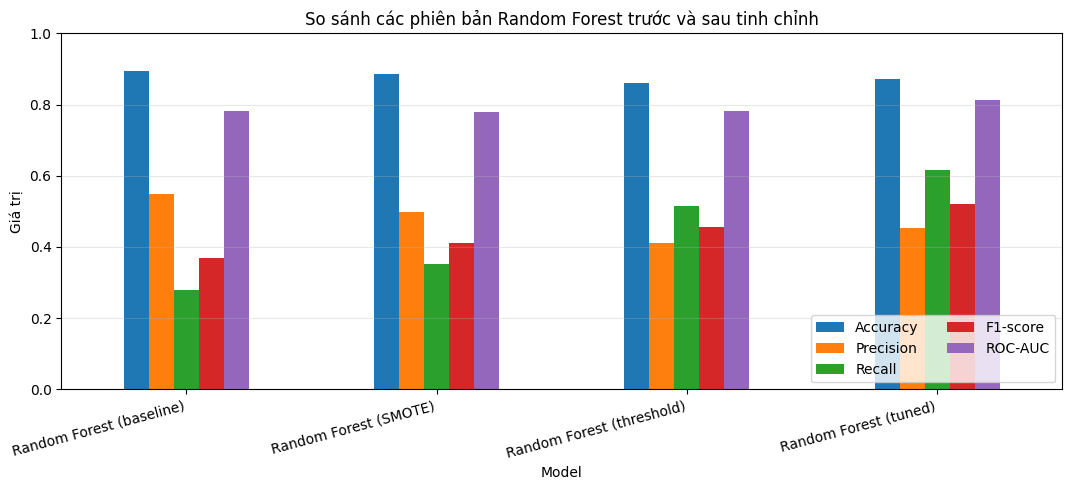

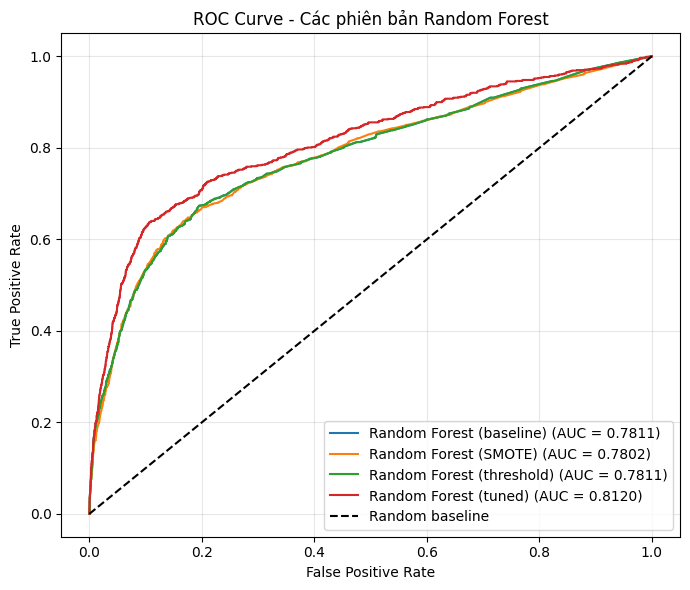

In [12]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Lấy kết quả từ all_results (hoặc đọc từ Experiments/Logs nếu chưa chạy các cell trên)
if "all_results" in globals() and len(all_results) > 0:
    df_rf_compare = pd.DataFrame(all_results).drop_duplicates(subset="Model", keep="last")
else:
    logs_dir = Path.cwd().resolve().parents[1] / "notebooks" / "02_EDA" / "Experiments" / "Logs"
    exp_dirs = [
        ("Random Forest (baseline)", "Experiment_04_RandomForest_baseline"),
        ("Random Forest (SMOTE)", "Experiment_08_RandomForest_SMOTE"),
        ("Random Forest (threshold=0.25)", "Experiment_12_RandomForest_threshold"),
        ("Random Forest (tuned)", "Experiment_16_RandomForest_tuned"),
    ]
    rows = []
    for label, dname in exp_dirs:
        mfile = logs_dir / dname / "metrics.json"
        if mfile.exists():
            with open(mfile, "r", encoding="utf-8") as f:
                m = json.load(f)
            rows.append({"Model": label, **m})
    df_rf_compare = pd.DataFrame(rows)

display(df_rf_compare.round(4))

# Biểu đồ cột so sánh các độ đo
metrics_cols = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
ax = df_rf_compare.set_index("Model")[metrics_cols].plot(kind="bar", figsize=(11, 5))
ax.set_title("So sánh các phiên bản Random Forest trước và sau tinh chỉnh")
ax.set_ylabel("Giá trị")
ax.set_ylim(0, 1.0)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

# Biểu đồ ROC Curve so sánh nếu có all_probas
if "all_probas" in globals() and len(all_probas) > 0:
    plt.figure(figsize=(7, 6))
    for name, proba in all_probas.items():
        fpr, tpr, _ = roc_curve(y_test, proba)
        auc_val = roc_auc_score(y_test, proba)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})")
    plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
    plt.title("ROC Curve - Các phiên bản Random Forest")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

**Nhận xét so sánh trước và sau tinh chỉnh:**

- **Baseline (`EXP-04`)**: Accuracy cao (0,8930) nhưng Recall rất thấp (0,2780), F1-score chỉ đạt 0,3694 do cây không giới hạn độ sâu (`max_depth=None`) bị overfitting vào lớp đa số `no`.
- **SMOTE (`EXP-08`)**: Recall tăng nhẹ lên 0,3481, F1 đạt 0,4081, nhưng ROC-AUC hơi giảm (0,7793) do dữ liệu One-Hot tạo mẫu nội suy nhiễu.
- **Threshold Tuning (`EXP-12`)**: Hạ ngưỡng từ 0,5 xuống 0,25 giúp Recall nhảy lên 0,5162 và F1 tăng lên 0,4571 mà không cần huấn luyện lại mô hình.
- **Hyperparameter Tuning (`EXP-16`)**: Đạt kết quả **tốt nhất toàn diện** với **F1-score = 0,5217** (+0,1523 so với baseline), **Recall = 0,6153** và **ROC-AUC = 0,8120**. Việc giới hạn `max_depth=15`, `min_samples_leaf=3`, `min_samples_split=10` giúp mô hình tổng quát hóa tốt hơn hẳn.

### 12. Phân tích mô hình

#### 12.1. Độ quan trọng của đặc trưng (Feature Importance)

So sánh Top 10 đặc trưng quan trọng nhất giữa **Random Forest Baseline** và **Random Forest Tuned** để xem việc tinh chỉnh siêu tham số làm thay đổi trọng tâm của mô hình như thế nào.

Top 10 đặc trưng quan trọng nhất - Random Forest (Tuned):
num__euribor3m           0.1596
num__nr.employed         0.1146
num__emp.var.rate        0.0876
num__age                 0.0633
num__cons.conf.idx       0.0559
num__cons.price.idx      0.0448
num__pdays               0.0406
num__campaign            0.0354
cat__poutcome_success    0.0327
cat__month_may           0.0233
dtype: float64


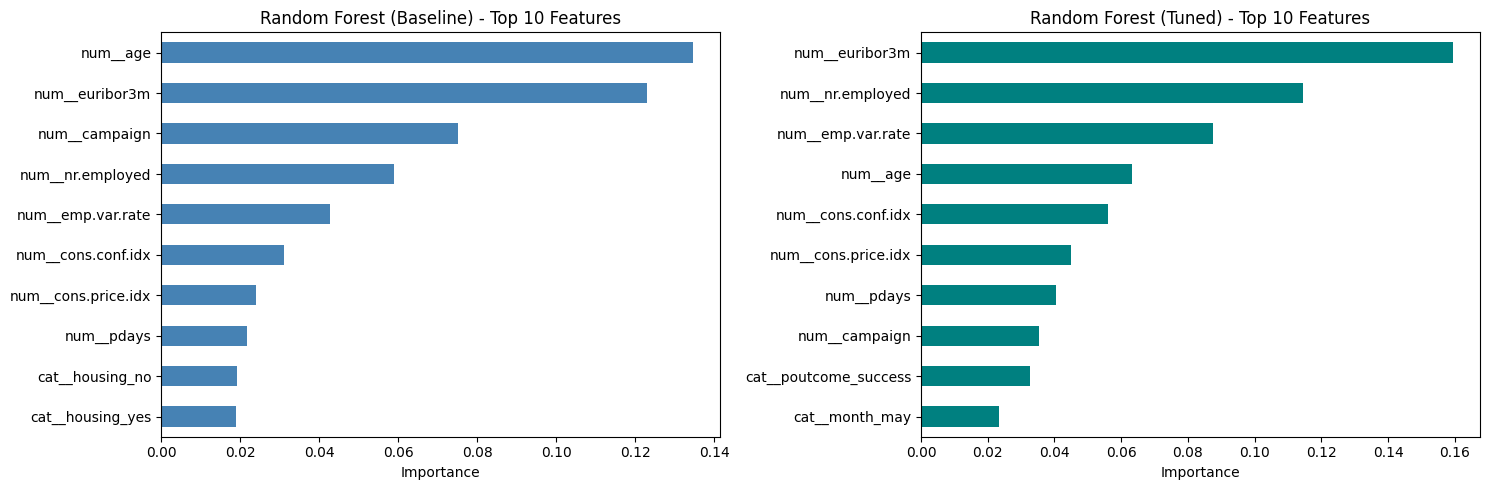

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

importance_rf_base = pd.Series(model_rf.feature_importances_, index=feature_names)
importance_rf_tuned = pd.Series(model_rf_tuned.feature_importances_, index=feature_names)

top10_base = importance_rf_base.sort_values(ascending=False).head(10)
top10_tuned = importance_rf_tuned.sort_values(ascending=False).head(10)

print("Top 10 đặc trưng quan trọng nhất - Random Forest (Tuned):")
print(top10_tuned.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top10_base.sort_values().plot(kind="barh", color="steelblue", ax=axes[0])
axes[0].set_title("Random Forest (Baseline) - Top 10 Features")
axes[0].set_xlabel("Importance")

top10_tuned.sort_values().plot(kind="barh", color="teal", ax=axes[1])
axes[1].set_title("Random Forest (Tuned) - Top 10 Features")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()

**Nhận xét:**

- **Random Forest Baseline** chia độ quan trọng cho các biến liên tục nhiều giá trị như `age`, `campaign` bên cạnh `euribor3m`, `nr.employed`.
- **Random Forest Tuned** tập trung mạnh hơn vào nhóm chỉ số kinh tế vĩ mô (`euribor3m`, `nr.employed`, `emp.var.rate`, `cons.conf.idx`) và lịch sử liên hệ (`pdays`, `poutcome_success`), phản ánh đúng bản chất bài toán: quyết định gửi tiền kỳ hạn chịu tác động lớn từ lãi suất và tình hình kinh tế tại thời điểm gọi.

#### 12.2. Phân tích lỗi (Error Analysis)

Phân tích các ca dự đoán sai của mô hình tốt nhất (**Random Forest Tuned - EXP-16**) trên tập test:
- **False Negative (FN)**: Khách hàng thực tế có đăng ký (`y=1`) nhưng mô hình đoán `0` → bỏ lỡ khách hàng tiềm năng.
- **False Positive (FP)**: Khách hàng thực tế không đăng ký (`y=0`) nhưng mô hình đoán `1` → tốn chi phí gọi điện không cần thiết.

In [14]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import confusion_matrix

# Đọc X_test_raw để phân tích trên giá trị gốc dễ đọc (tuổi, campaign, euribor3m...)
raw_test_path = Path.cwd().resolve().parents[1] / "DATA" / "processed" / "X_test_raw.csv"
if "X_test_raw" in globals():
    df_err = X_test_raw.copy().reset_index(drop=True)
elif raw_test_path.exists():
    df_err = pd.read_csv(raw_test_path)
else:
    df_err = pd.DataFrame(X_test, columns=feature_names)

df_err["y_true"] = pd.Series(y_test).reset_index(drop=True)
df_err["y_pred"] = pd.Series(y_pred_rf_tuned).reset_index(drop=True)
df_err["y_proba"] = pd.Series(y_proba_rf_tuned).reset_index(drop=True)

tn, fp, fn, tp = confusion_matrix(df_err["y_true"], df_err["y_pred"]).ravel()
print(f"TP (Đoán đúng Yes): {tp} | FN (Bỏ sót Yes): {fn}")
print(f"TN (Đoán đúng No) : {tn} | FP (Gọi nhầm No) : {fp}")

def classify_error(row):
    if row["y_true"] == 1 and row["y_pred"] == 1:
        return "TP"
    if row["y_true"] == 0 and row["y_pred"] == 0:
        return "TN"
    if row["y_true"] == 0 and row["y_pred"] == 1:
        return "FP"
    return "FN"

df_err["error_type"] = df_err.apply(classify_error, axis=1)

# So sánh giá trị trung bình của các biến số chính theo từng nhóm TP / FN / FP / TN
num_cols = [c for c in ["age", "campaign", "pdays", "previous", "emp.var.rate", "euribor3m", "nr.employed"] if c in df_err.columns]
if num_cols:
    print("\nTrung bình các đặc trưng số theo nhóm dự đoán:")
    display(df_err.groupby("error_type")[num_cols + ["y_proba"]].mean().round(3))

# Xem 5 ca False Negative có xác suất dự đoán thấp nhất (mô hình tự tin sai nhất)
print("\nTop 5 False Negative (khách thật sự đăng ký nhưng mô hình đoán xác suất thấp nhất):")
display(df_err[df_err["error_type"] == "FN"].sort_values("y_proba").head(5))

TP (Đoán đúng Yes): 571 | FN (Bỏ sót Yes): 357
TN (Đoán đúng No) : 6618 | FP (Gọi nhầm No) : 690

Trung bình các đặc trưng số theo nhóm dự đoán:


,age,campaign,pdays,previous,emp.var.rate,euribor3m,nr.employed,y_proba
error_type,,,,,,,,
FN,39.020,2.583,993.451,0.115,0.167,3.673,5175.544,0.285
FP,41.104,1.988,859.357,0.478,-2.330,1.099,5056.119,0.701
TN,39.886,2.730,995.399,0.093,0.537,4.120,5189.681,0.244
TP,41.331,1.716,677.179,0.720,-2.227,1.045,5040.708,0.775



Top 5 False Negative (khách thật sự đăng ký nhưng mô hình đoán xác suất thấp nhất):


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y_true,y_pred,y_proba,error_type
1845,42,self-employed,married,university.degree,no,yes,no,telephone,jul,thu,...,nonexistent,1.4,93.918,-42.7,4.968,5228.1,1,0,0.071018,FN
7990,32,admin.,married,university.degree,no,no,yes,telephone,may,fri,...,nonexistent,1.1,93.994,-36.4,4.855,5191.0,1,0,0.089291,FN
3766,53,blue-collar,married,basic.4y,unknown,no,no,telephone,may,tue,...,nonexistent,1.1,93.994,-36.4,4.856,5191.0,1,0,0.089925,FN
3557,34,admin.,divorced,university.degree,no,no,no,telephone,jul,thu,...,nonexistent,1.4,93.918,-42.7,4.966,5228.1,1,0,0.097956,FN
2999,38,management,married,basic.9y,unknown,no,no,telephone,may,fri,...,nonexistent,1.1,93.994,-36.4,4.855,5191.0,1,0,0.098372,FN


**Nhận xét phân tích lỗi:**

- Mô hình vẫn còn một lượng **False Negative** (bỏ sót khách hàng thực sự đăng ký) khi xác suất dự đoán rơi ngay dưới ngưỡng 0,5 (thường tập trung ở nhóm khách hàng có chỉ số kinh tế `euribor3m` / `nr.employed` không thuận lợi nhưng vẫn quyết định gửi tiền do yếu tố cá nhân không có trong dữ liệu).
- Nhóm **False Positive** thường là những khách hàng có hồ sơ giống người đăng ký (từng được liên hệ trước đó hoặc gọi trong giai đoạn lãi suất thấp) nhưng cuối cùng từ chối. Trong thực tế ngân hàng, chi phí của **FN** (mất khách gửi tiền) cao hơn **FP** (tốn 1 cuộc gọi), nên việc hạ ngưỡng nhẹ dưới 0,5 có thể được cân nhắc thêm nếu muốn tối đa hóa số khách thu hút.

### 13. Lưu mô hình

Lưu mô hình tốt nhất (**Random Forest Tuned - EXP-16**) bằng `joblib` và kiểm tra đọc lại từ file `.pkl` để đảm bảo mô hình có thể tái sử dụng cho dự đoán thực tế.

In [15]:
from pathlib import Path
import joblib
import numpy as np

save_dir = Path.cwd().resolve().parents[1] / "notebooks" / "02_EDA" / "Experiments" / "Logs" / "Experiment_16_RandomForest_tuned"
save_dir.mkdir(parents=True, exist_ok=True)
model_path = save_dir / "best_model.pkl"

# Lưu mô hình
joblib.dump(model_rf_tuned, model_path)
print(f"Đã lưu mô hình tốt nhất tại: {model_path}")

# Kiểm tra load lại và đối chiếu dự đoán
loaded_model = joblib.load(model_path)
sample_pred = loaded_model.predict(X_test[:5])
sample_proba = loaded_model.predict_proba(X_test[:5])[:, 1]

assert np.array_equal(sample_pred, y_pred_rf_tuned[:5]), "Dự đoán sau khi load không khớp!"
print("Kiểm tra load lại thành công! Dự đoán 5 mẫu đầu:", sample_pred)
print("Xác suất tương ứng:", np.round(sample_proba, 4))

Đã lưu mô hình tốt nhất tại: C:\Users\Chau\Documents\MayHoc_nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_16_RandomForest_tuned\best_model.pkl
Kiểm tra load lại thành công! Dự đoán 5 mẫu đầu: [0 1 0 0 0]
Xác suất tương ứng: [0.1235 0.9583 0.4317 0.4836 0.3415]
